# MBA · Machine Learning e Hiperpersonalização
## Atividade 1 — Treinamento do modelo de churn da EnglishPro
**Aula de 28 de outubro de 2026 · Vibe Coding Executivo**

Este notebook executa os dois prompts da Atividade 1 com cálculos reais: explorar o histórico, comparar dois modelos e explicar os resultados para a gestão. A previsão é de cancelamento nos **60 dias seguintes à observação**.

**Como usar:** no VS Code, abra este arquivo, escolha o interpretador `.venv/bin/python` desta pasta como kernel e clique em **Run All / Executar tudo**. Os resultados desta entrega já estão salvos nas células. Para Google Colab, envie este notebook e a planilha de treino na barra Arquivos; o localizador abaixo também procura em `/content`.

**Entregas:** exploração, dicionário, médias por grupo, comparação por AUC, matriz de confusão, importância e direção das variáveis, dois alunos fictícios e modelo salvo. A Atividade 2 (previsão dos alunos atuais) e a integração Lovable da Atividade 3 ficam para os próximos exercícios.

**Fontes locais:** `Atividade 1 - EnglishPro_Exercicio_Treinamento do modelo.docx` e `Atividade 1 - EnglishPro_Churn_Treino.xlsx`, na pasta `Aula 04 - Atividades ` (o nome termina em espaço). O enunciado foi transcrito em `enunciado-atividade-1.txt`.

### 1. Preparar o ambiente
O ambiente local já foi instalado. A célula de instalação fica desativada para não alterar dependências a cada execução. No Colab ou em outro ambiente, descomente a linha `%pip` e execute antes das importações. As versões exatas usadas nesta entrega estão em `requirements.txt`.

In [1]:
# %pip install pandas openpyxl scikit-learn matplotlib nbformat nbclient ipykernel joblib

In [2]:
from pathlib import Path
import hashlib, json, sys, platform
from importlib.metadata import version
from datetime import datetime
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, brier_score_loss, confusion_matrix,
    RocCurveDisplay, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

SEMENTE = 42
FRACAO_TESTE = 0.25
LIMIAR = 0.50  # ilustrativo; não foi otimizado no teste
# Opcional: informe o caminho completo da sua planilha.
ARQUIVO_TREINO = None

PASTA_SAIDA = Path.cwd() / 'resultados'
PASTA_SAIDA.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth', 150)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', platform.python_version())
print('scikit-learn:', version('scikit-learn'))
print('Resultados:', PASTA_SAIDA)

Python: 3.12.14
scikit-learn: 1.9.1
Resultados: /Users/afigueiredo/Documents/ChatGPT/mba-ai-leadership-4abl/disciplinas/21-vibe-coding-executivo/aulas/Aula-04/atividade-1-notebook/resultados


### 2. Ingerir e validar a planilha
A aba `base_treinamento` contém as observações; `dicionario_features` define as colunas. O identificador é preservado para rastreabilidade e excluído das entradas. Os controles interrompem o treinamento se houver dados incompatíveis. As taxas são proporções entre 0 e 1.

In [3]:
if ARQUIVO_TREINO:
    arquivo = Path(ARQUIVO_TREINO).expanduser().resolve()
else:
    candidatos = []
    bases = [Path.cwd(), Path.cwd().parent, Path('/content')]
    for base in bases:
        if base.exists():
            candidatos.extend(base.glob('*Churn_Treino.xlsx'))
            candidatos.extend(base.glob('Aula 04 - Atividades*/*Churn_Treino.xlsx'))
    candidatos = sorted(set(p.resolve() for p in candidatos))
    if len(candidatos) != 1:
        raise FileNotFoundError('Defina ARQUIVO_TREINO com o caminho da planilha; encontrados: ' + str(candidatos))
    arquivo = candidatos[0]

FEATURES = ['tempo_casa_meses', 'taxa_inadimplencia_historica',
            'n_parcelas_atrasadas_90_dias', 'taxa_presenca_30_dias',
            'n_acessos_plataforma_30_dias']
ALVO = 'cancelou_60_dias'
df = pd.read_excel(arquivo, sheet_name='base_treinamento')
dicionario = pd.read_excel(arquivo, sheet_name='dicionario_features')
assert set(df.columns) == set(['id_aluno', *FEATURES, ALVO]), 'Colunas inesperadas'
assert not df.empty and not df.isna().any().any(), 'Base vazia ou valores ausentes'
assert df['id_aluno'].is_unique, 'IDs duplicados'
for col in df.columns:
    assert pd.api.types.is_numeric_dtype(df[col]), f'Coluna não numérica: {col}'
    assert np.isfinite(df[col]).all(), f'Valor infinito: {col}'
assert set(df[ALVO].unique()) == {0, 1}, 'Rótulo deve ser binário'
for col in ['taxa_inadimplencia_historica', 'taxa_presenca_30_dias']:
    assert df[col].between(0, 1).all(), f'Taxa fora da escala: {col}'
for col in ['id_aluno', 'tempo_casa_meses', 'n_parcelas_atrasadas_90_dias', 'n_acessos_plataforma_30_dias']:
    assert (df[col] >= 0).all() and (df[col] % 1 == 0).all(), f'Contagem inválida: {col}'
HASH_FONTE = hashlib.sha256(arquivo.read_bytes()).hexdigest()
print('Arquivo:', arquivo.name)
print('Dimensão:', df.shape, '| SHA-256:', HASH_FONTE)
display(df.head())
display(dicionario)
dicionario.to_csv(PASTA_SAIDA/'dicionario_features.csv', index=False)

Arquivo: Atividade 1 - EnglishPro_Churn_Treino.xlsx
Dimensão: (5400, 7) | SHA-256: ba6c067b961bcf27fa343e777b258eb0fbfc299fab6586f80cacbf2d3b811a19


,id_aluno,tempo_casa_meses,taxa_inadimplencia_historica,n_parcelas_atrasadas_90_dias,taxa_presenca_30_dias,n_acessos_plataforma_30_dias,cancelou_60_dias
0,1,22,0.000,0,0.769,30,0
1,2,61,0.000,0,0.370,10,0
2,3,29,0.225,1,0.540,20,0
3,4,4,0.000,0,0.000,12,0
4,5,9,0.000,0,0.029,10,0


,Coluna,Tipo,Descrição e Tabela de Origem
0,id_aluno,Identificação,Identificador do aluno. NÃO é feature — excluir antes de treinar.
1,tempo_casa_meses,Feature — Cadastral,Meses desde a data de matrícula até a data de observação. Vem de: matricula.data_matricula
2,taxa_inadimplencia_historica,Feature — Financeira,Proporção de parcelas com status 'atrasado' sobre o total de parcelas vencidas até a data de observação. Vem de: pagamento.status_pagamento
3,n_parcelas_atrasadas_90_dias,Feature — Financeira,Contagem de parcelas com status 'atrasado' e data_vencimento nos 90 dias anteriores à data de observação. Vem de: pagamento
4,taxa_presenca_30_dias,Feature — Pedagógica,Proporção de aulas com presença = 'Sim' nos 30 dias anteriores à data de observação. Vem de: presenca (join com matricula para ligar ao aluno)
5,n_acessos_plataforma_30_dias,Feature — Engajamento,Contagem de sessões na plataforma digital (linhas em uso_plataforma) nos 30 dias anteriores à data de observação. Vem de: uso_plataforma.data_acesso
6,cancelou_60_dias,LABEL,"1 se o aluno cancelou nos 60 dias APÓS a data de observação, 0 caso contrário. NUNCA usar como feature. É o que o modelo aprende a prever."


### 3. Explorar a base — resposta ao Prompt 1
Compare as médias na unidade original. Para identificar duas diferenças de destaque sem comparar meses com percentuais, usamos também a diferença padronizada: diferença entre médias dividida pelo desvio-padrão da variável na base inteira. É uma descrição da amostra, sem significado causal.

**5,400 alunos**, dos quais **1,110 cancelaram (20.56%)** e **4,290 permaneceram**.

,não_cancelou,cancelou,diferença,diferença_padronizada
taxa_presenca_30_dias,0.6784,0.4335,-0.2450,-1.0320
n_acessos_plataforma_30_dias,24.5219,15.6360,-8.8859,-0.8938
n_parcelas_atrasadas_90_dias,0.3916,1.0838,0.6922,0.7828
taxa_inadimplencia_historica,0.0896,0.1969,0.1073,0.7305
tempo_casa_meses,14.5009,9.0207,-5.4802,-0.3876


As duas maiores diferenças padronizadas:
- taxa_presenca_30_dias: 0.678 em quem permaneceu e 0.433 em quem cancelou.
- n_acessos_plataforma_30_dias: 24.522 em quem permaneceu e 15.636 em quem cancelou.


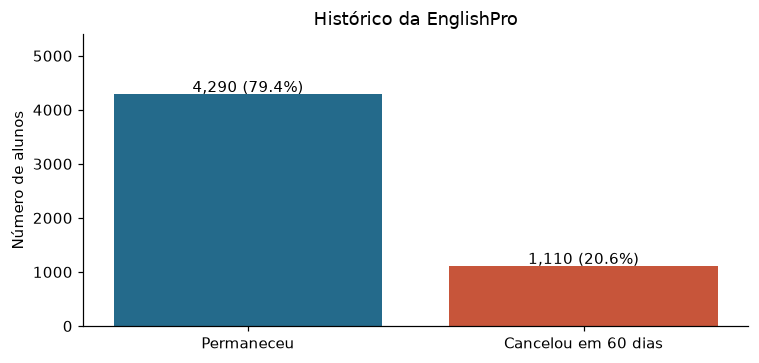

In [4]:
n_cancelaram = int(df[ALVO].sum())
taxa_churn = float(df[ALVO].mean())
display(Markdown(f'**{len(df):,} alunos**, dos quais **{n_cancelaram:,} cancelaram ({taxa_churn:.2%})** e **{len(df)-n_cancelaram:,} permaneceram**.'))
medias = df.groupby(ALVO)[FEATURES].mean().T
medias.columns = ['não_cancelou', 'cancelou']
medias['diferença'] = medias['cancelou'] - medias['não_cancelou']
medias['diferença_padronizada'] = medias['diferença'] / df[FEATURES].std()
medias = medias.sort_values('diferença_padronizada', key=abs, ascending=False)
display(medias.round(4))
print('As duas maiores diferenças padronizadas:')
for feature, row in medias.head(2).iterrows():
    print(f"- {feature}: {row['não_cancelou']:.3f} em quem permaneceu e {row['cancelou']:.3f} em quem cancelou.")
medias.to_csv(PASTA_SAIDA/'medias_por_grupo.csv')
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(['Permaneceu', 'Cancelou em 60 dias'], [len(df)-n_cancelaram, n_cancelaram], color=['#246a8b', '#c7553a'])
ax.set(ylabel='Número de alunos', title='Histórico da EnglishPro')
for i, n in enumerate([len(df)-n_cancelaram, n_cancelaram]):
    ax.text(i, n+40, f'{n:,} ({n/len(df):.1%})', ha='center')
ax.set_ylim(0, len(df))
fig.tight_layout(); fig.savefig(PASTA_SAIDA/'distribuicao_churn.png'); plt.show()

### 4. Separar 75% para treino e 25% para teste
A divisão é estratificada para manter proporções semelhantes de cancelamento. Todo pré-processamento é ajustado somente no treino, dentro de pipelines. O teste não participa do ajuste nem da escolha de hiperparâmetros.

Conforme o enunciado, o vencedor será escolhido pelo AUC do teste. Isso torna essa métrica uma medida de seleção; para uma estimativa final independente em produção seria necessária outra amostra ou validação externa. Não repetimos divisões até obter uma nota desejada.

In [5]:
X, y = df[FEATURES], df[ALVO].astype(int)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=FRACAO_TESTE, random_state=SEMENTE, stratify=y)
assert len(set(X_treino.index) & set(X_teste.index)) == 0
assert len(X_teste) == len(df)*FRACAO_TESTE
assert 'id_aluno' not in X.columns and ALVO not in X.columns
particoes = df[['id_aluno', ALVO]].copy()
particoes['particao'] = np.where(df.index.isin(X_teste.index), 'teste', 'treino')
particoes.to_csv(PASTA_SAIDA/'particoes.csv', index=False)
display(pd.DataFrame({'alunos': [len(y_treino), len(y_teste)],
    'taxa_cancelamento': [y_treino.mean(), y_teste.mean()]}, index=['Treino', 'Teste']))

,alunos,taxa_cancelamento
Treino,4050,0.205679
Teste,1350,0.205185


### 5. Treinar e avaliar dois modelos — resposta ao Prompt 2
Regressão logística permite interpretar associações; random forest captura relações não lineares. Os parâmetros foram definidos antes da avaliação. Um modelo constante representa a referência sem informação.

**AUC** mede ordenação do risco, não percentual de acertos. Por exemplo, AUC de 0,85 corresponde a cerca de 85% de chance de ordenar acima um aluno que cancelou ao comparar um par aleatório de cancelou/não cancelou. Precisão e recall abaixo usam limiar de 50%; Brier menor indica erro quadrático menor das probabilidades.

In [6]:
modelos = {
    'Regressão logística': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=SEMENTE)),
    'Random forest': make_pipeline(SimpleImputer(strategy='median'),
        RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                               random_state=SEMENTE, n_jobs=1))
}
resultados = []
probabilidades = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    p = modelo.predict_proba(X_teste)[:, 1]
    pred = (p >= LIMIAR).astype(int)
    probabilidades[nome] = p
    resultados.append({'modelo': nome, 'auc_teste': roc_auc_score(y_teste, p),
        'auc_treino': roc_auc_score(y_treino, modelo.predict_proba(X_treino)[:, 1]),
        'average_precision': average_precision_score(y_teste, p),
        'acuracia': accuracy_score(y_teste, pred),
        'precisao': precision_score(y_teste, pred, zero_division=0),
        'recall': recall_score(y_teste, pred), 'f1': f1_score(y_teste, pred),
        'brier': brier_score_loss(y_teste, p)})
metricas = pd.DataFrame(resultados).sort_values('auc_teste', ascending=False).reset_index(drop=True)
vencedor = str(metricas.iloc[0]['modelo'])
modelo = modelos[vencedor]
p_teste = probabilidades[vencedor]
baseline = DummyClassifier(strategy='prior').fit(X_treino, y_treino)
p_base = baseline.predict_proba(X_teste)[:, 1]
display(metricas.round(4))
print(f'Vencedor: {vencedor} | AUC de teste: {metricas.iloc[0]["auc_teste"]:.4f}')
print(f'Referência constante: AUC {roc_auc_score(y_teste, p_base):.4f}; Brier {brier_score_loss(y_teste, p_base):.4f}')
metricas.to_csv(PASTA_SAIDA/'comparacao_modelos.csv', index=False)

,modelo,auc_teste,auc_treino,average_precision,acuracia,precisao,recall,f1,brier
0,Random forest,0.8733,0.9655,0.6906,0.8593,0.7326,0.4946,0.5905,0.1034
1,Regressão logística,0.8699,0.8821,0.7020,0.8578,0.7322,0.4838,0.5826,0.1029


Vencedor: Random forest | AUC de teste: 0.8733
Referência constante: AUC 0.5000; Brier 0.1631


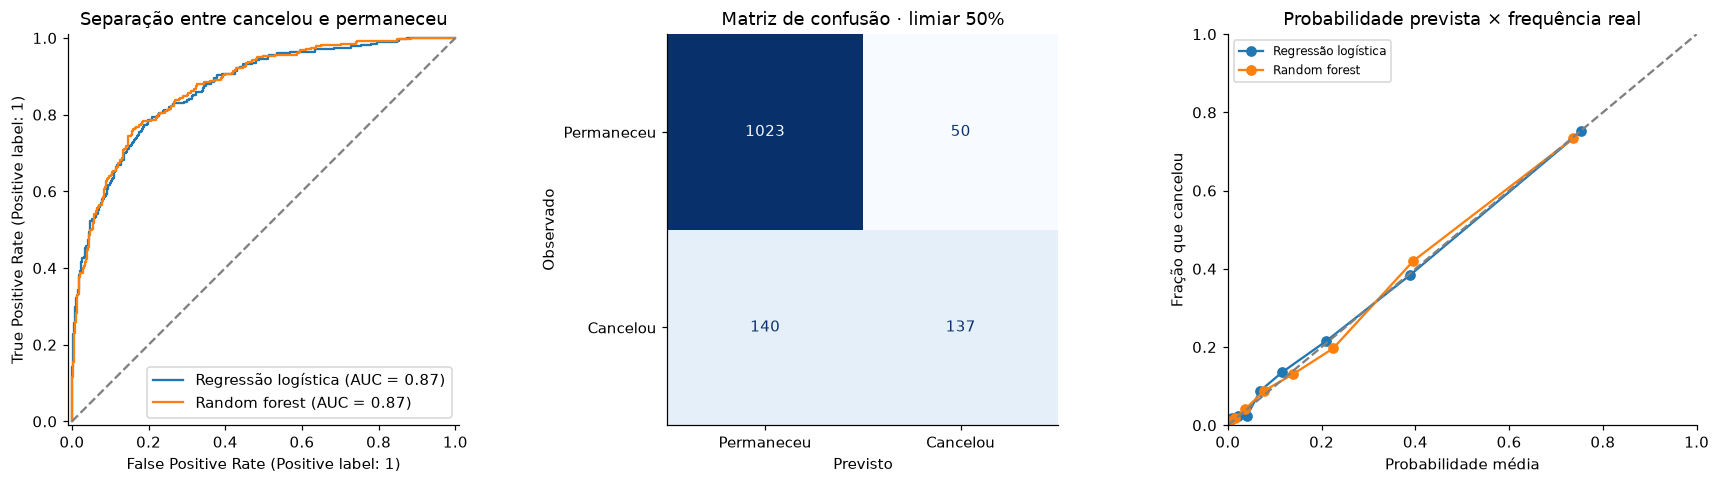

No teste: 1023 permanências corretas, 137 cancelamentos detectados, 50 falsos positivos e 140 falsos negativos.
Falso positivo: pode gerar desconto desnecessário. Falso negativo: pode deixar de atender um aluno que cancelará.


,limiar,alunos_sinalizados,precisao,recall,falsos_positivos,falsos_negativos
0,0.2,455,0.481,0.791,236,58
1,0.3,328,0.576,0.682,139,88
2,0.5,187,0.733,0.495,50,140
3,0.7,96,0.854,0.296,14,195


Comparação ilustrativa: não há custo de desconto/receita nem efeito de campanha medidos para otimizar o limiar.


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for nome, p in probabilidades.items():
    RocCurveDisplay.from_predictions(y_teste, p, name=nome, ax=axes[0])
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set_title('Separação entre cancelou e permaneceu')
ConfusionMatrixDisplay.from_predictions(y_teste, (p_teste >= LIMIAR).astype(int),
    display_labels=['Permaneceu', 'Cancelou'], cmap='Blues', colorbar=False, ax=axes[1])
axes[1].set(title='Matriz de confusão · limiar 50%', xlabel='Previsto', ylabel='Observado')
for nome, p in probabilidades.items():
    observado, previsto = calibration_curve(y_teste, p, n_bins=8, strategy='quantile')
    axes[2].plot(previsto, observado, 'o-', label=nome)
axes[2].plot([0, 1], [0, 1], '--', color='gray')
axes[2].set(title='Probabilidade prevista × frequência real', xlabel='Probabilidade média', ylabel='Fração que cancelou', xlim=(0,1), ylim=(0,1))
axes[2].legend(fontsize=8)
fig.tight_layout(); fig.savefig(PASTA_SAIDA/'avaliacao_modelos.png', bbox_inches='tight'); plt.show()
tn, fp, fn, tp = confusion_matrix(y_teste, p_teste >= LIMIAR).ravel()
print(f'No teste: {tn} permanências corretas, {tp} cancelamentos detectados, {fp} falsos positivos e {fn} falsos negativos.')
print('Falso positivo: pode gerar desconto desnecessário. Falso negativo: pode deixar de atender um aluno que cancelará.')
limiares = []
for corte in [0.2, 0.3, 0.5, 0.7]:
    pred = p_teste >= corte
    a,b,c,d = confusion_matrix(y_teste,pred).ravel()
    limiares.append({'limiar':corte,'alunos_sinalizados':int(pred.sum()),'precisao':precision_score(y_teste,pred,zero_division=0),'recall':recall_score(y_teste,pred),'falsos_positivos':int(b),'falsos_negativos':int(c)})
display(pd.DataFrame(limiares).round(3))
print('Comparação ilustrativa: não há custo de desconto/receita nem efeito de campanha medidos para otimizar o limiar.')

### 6. Explicar as cinco variáveis
A importância por permutação mede a queda de AUC ao embaralhar uma variável no teste (10 repetições). Valores maiores indicam mais contribuição; valores negativos ou próximos de zero podem refletir ruído ou redundância.

Para mostrar a **direção**, substituímos uma variável de cada vez pelos percentis 25 e 75 do treino e calculamos a diferença média no risco sobre as linhas de teste. Esse contraste resume o comportamento do modelo; pode ocultar relações não lineares e criar combinações pouco frequentes. Mostramos também os coeficientes padronizados da regressão logística. Associação e previsão não demonstram causalidade.

,feature,queda_auc_media,desvio_repeticoes,q25_treino,q75_treino,contraste_risco_pp,direcao_no_contraste
3,taxa_presenca_30_dias,0.0941,0.0073,0.509,0.809,-10.0605,reduz
2,n_parcelas_atrasadas_90_dias,0.0608,0.0064,0.000,1.000,7.8165,aumenta
1,taxa_inadimplencia_historica,0.0520,0.0046,0.000,0.188,4.0693,aumenta
0,tempo_casa_meses,0.0326,0.0052,3.000,20.000,-11.6566,reduz
4,n_acessos_plataforma_30_dias,0.0301,0.0039,16.000,30.000,-10.4613,reduz


,feature,coeficiente_padronizado,razao_de_chances_por_desvio_padrao
0,tempo_casa_meses,-0.7229,0.4853
1,taxa_inadimplencia_historica,0.5235,1.6879
2,n_parcelas_atrasadas_90_dias,0.7313,2.0778
3,taxa_presenca_30_dias,-0.9071,0.4037
4,n_acessos_plataforma_30_dias,-0.6437,0.5254


Coeficiente positivo aumenta as chances na regressão logística; negativo reduz, mantendo as demais entradas constantes.


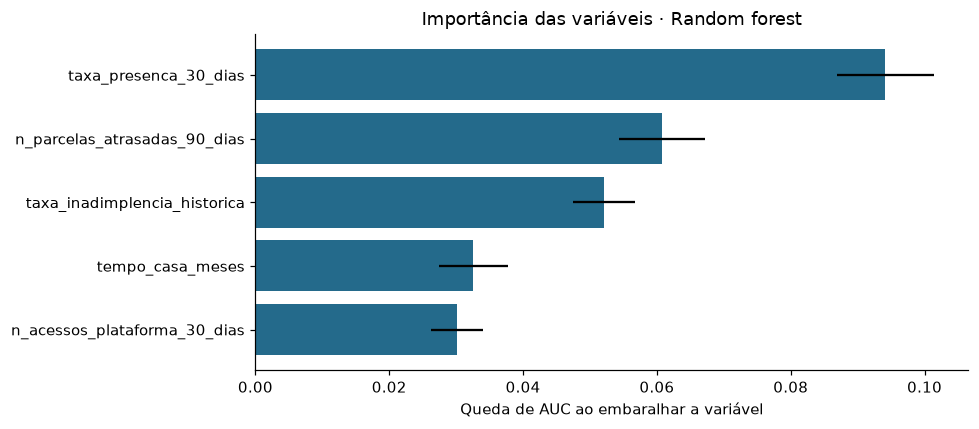

In [8]:
perm = permutation_importance(modelo, X_teste, y_teste, scoring='roc_auc',
    n_repeats=10, random_state=SEMENTE, n_jobs=1)
importancia = pd.DataFrame({'feature':FEATURES, 'queda_auc_media':perm.importances_mean,
                           'desvio_repeticoes':perm.importances_std})
contrastes = []
for feature in FEATURES:
    q25, q75 = X_treino[feature].quantile([0.25,0.75])
    baixo, alto = X_teste.copy(), X_teste.copy()
    baixo[feature], alto[feature] = q25, q75
    delta = float(np.mean(modelo.predict_proba(alto)[:,1] - modelo.predict_proba(baixo)[:,1])*100)
    contrastes.append({'feature':feature,'q25_treino':float(q25),'q75_treino':float(q75),
        'contraste_risco_pp':delta,'direcao_no_contraste':('aumenta' if delta>0 else 'reduz' if delta<0 else 'sem variação')})
importancia = importancia.merge(pd.DataFrame(contrastes), on='feature').sort_values('queda_auc_media', ascending=False)
display(importancia.round(4))
coef = pd.DataFrame({'feature':FEATURES,
    'coeficiente_padronizado':modelos['Regressão logística'].steps[-1][1].coef_[0]})
coef['razao_de_chances_por_desvio_padrao'] = np.exp(coef['coeficiente_padronizado'])
display(coef.round(4))
print('Coeficiente positivo aumenta as chances na regressão logística; negativo reduz, mantendo as demais entradas constantes.')
importancia.to_csv(PASTA_SAIDA/'importancia_variaveis.csv', index=False)
coef.to_csv(PASTA_SAIDA/'coeficientes_logistica.csv', index=False)
fig, ax = plt.subplots(figsize=(9,4))
imp_plot = importancia.sort_values('queda_auc_media')
ax.barh(imp_plot['feature'],imp_plot['queda_auc_media'],xerr=imp_plot['desvio_repeticoes'], color='#246a8b')
ax.axvline(0,color='gray',linewidth=1)
ax.set(xlabel='Queda de AUC ao embaralhar a variável',title=f'Importância das variáveis · {vencedor}')
fig.tight_layout(); fig.savefig(PASTA_SAIDA/'importancia_variaveis.png', bbox_inches='tight'); plt.show()

### 7. Calcular o risco de dois alunos fictícios
São exemplos didáticos, sem identificação de pessoas reais. As probabilidades são calculadas pelo vencedor já ajustado, sem novo treino. Os valores estão dentro dos limites observados na base; a combinação das características pode ser menos frequente que cada valor isolado.

In [9]:
exemplos = pd.DataFrame([
    [24, 0.0, 0, 0.90, 40],
    [2, 0.50, 3, 0.20, 4]], columns=FEATURES,
    index=['Perfil de permanência', 'Perfil de atenção'])
assert exemplos.ge(X.min()).all().all() and exemplos.le(X.max()).all().all()
exemplos['probabilidade_churn_pct'] = (modelo.predict_proba(exemplos[FEATURES])[:,1]*100).round(1)
display(exemplos)
exemplos.to_csv(PASTA_SAIDA/'alunos_ficticios.csv')
print('O modelo estima risco de cancelamento; não estima a chance de aceitar um desconto nem o efeito de uma intervenção.')

,tempo_casa_meses,taxa_inadimplencia_historica,n_parcelas_atrasadas_90_dias,taxa_presenca_30_dias,n_acessos_plataforma_30_dias,probabilidade_churn_pct
Perfil de permanência,24,0.0,0,0.9,40,0.0
Perfil de atenção,2,0.5,3,0.2,4,97.3


O modelo estima risco de cancelamento; não estima a chance de aceitar um desconto nem o efeito de uma intervenção.


### 8. Registrar a conclusão e salvar o modelo
O arquivo contém exatamente o pipeline vencedor treinado nos 75% reservados; não há re-treino sobre o teste. Ele pode ser reutilizado na Atividade 2. Arquivos `joblib` devem ser carregados apenas quando a origem é conhecida, no mesmo ambiente de bibliotecas.

In [10]:
artefato = {'modelo':modelo, 'features':FEATURES, 'alvo':ALVO, 'vencedor':vencedor,
            'semente':SEMENTE, 'hash_fonte':HASH_FONTE,
            'versoes':{p:version(p) for p in ['pandas','numpy','scikit-learn','joblib']}}
joblib.dump(artefato, PASTA_SAIDA/'modelo_churn.joblib')
reaberto = joblib.load(PASTA_SAIDA/'modelo_churn.joblib')
assert np.allclose(reaberto['modelo'].predict_proba(X_teste)[:,1], p_teste)
previsoes_teste = df.loc[X_teste.index,['id_aluno',ALVO]].copy()
previsoes_teste['probabilidade_churn'] = p_teste
previsoes_teste.to_csv(PASTA_SAIDA/'previsoes_teste.csv', index=False)
resumo = {'data_execucao':datetime.now(ZoneInfo('America/Sao_Paulo')).isoformat(),
    'aula':'2026-10-28','arquivo_fonte':arquivo.name,'sha256_fonte':HASH_FONTE,
    'alunos':len(df),'cancelamentos':n_cancelaram,'taxa_churn':taxa_churn,
    'treino':len(y_treino),'teste':len(y_teste),'semente':SEMENTE,
    'vencedor':vencedor,'metricas':metricas.to_dict(orient='records'),
    'limiar_ilustrativo':LIMIAR,'matriz_confusao':{'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)},
    'exemplos':exemplos.reset_index().to_dict(orient='records'), 'versoes':artefato['versoes']}
(PASTA_SAIDA/'resumo_execucao.json').write_text(json.dumps(resumo,ensure_ascii=False,indent=2),encoding='utf-8')
linhas = [f'EnglishPro — Atividade 1 — Aula de 28/10/2026',
    f'Base: {len(df)} alunos; {n_cancelaram} cancelamentos ({taxa_churn:.2%}).',
    f'Treino: {len(y_treino)}; teste: {len(y_teste)}. Semente: {SEMENTE}.',
    f'Vencedor: {vencedor}; AUC de teste: {metricas.iloc[0]["auc_teste"]:.4f}.',
    f'O modelo vencedor obteve o maior AUC entre as duas alternativas; a diferença isolada não comprova superioridade estatística.',
    f'No limiar de 50%: {fp} falsos positivos e {fn} falsos negativos.', '\nDuas diferenças de destaque:']
for feature,row in medias.head(2).iterrows():
    linhas.append(f'{feature}: permaneceu {row["não_cancelou"]:.3f}; cancelou {row["cancelou"]:.3f}.')
linhas += ['Menor presença/uso pode indicar desengajamento; atrasos podem indicar dificuldade financeira; tempo de casa pode refletir adaptação. São hipóteses de negócio, sem prova causal.', '\nVariáveis em ordem de importância e direção no contraste P25→P75:']
for _,row in importancia.iterrows():
    linhas.append(f'{row["feature"]}: queda AUC {row["queda_auc_media"]:.4f}; {row["direcao_no_contraste"]} o risco ({row["contraste_risco_pp"]:+.2f} pontos percentuais).')
linhas += ['\nAlunos fictícios:']
for nome,row in exemplos.iterrows():
    linhas.append(f'{nome}: {row["probabilidade_churn_pct"]:.1f}% de risco estimado.')
linhas += ['\nLimitações e conexão com hiperpersonalização:',
    'AUC mede ordenação, não garante probabilidades perfeitamente calibradas. Consulte o gráfico de calibração e o Brier.',
    'O AUC 0,870 anunciado na aba Leia-me é referência do material, não resultado garantido desta divisão.',
    'O teste foi usado para selecionar o vencedor conforme o roteiro; valide em outra amostra antes de uso operacional.',
    'As janelas das features devem terminar antes da janela futura de 60 dias. A base não contém datas para auditar essa sequência ou validar temporalmente.',
    'Risco pode orientar prioridade de atendimento; descontos, faixas e campanhas dependem de custos e experimento de retenção. Não há ganho financeiro medido neste exercício.',
    'Ações pedagógicas, apoio de adaptação ou negociação financeira são hipóteses coerentes com sinais de risco, a testar com grupo de controle.',
    'Não foram executadas a pontuação dos alunos atuais nem alterações no app (Atividades 2 e 3).']
relatorio = '\n'.join(linhas)
(PASTA_SAIDA/'conclusao_atividade_1.txt').write_text(relatorio,encoding='utf-8')
print(relatorio)
print('\nModelo salvo e recarregado com previsões idênticas.')

EnglishPro — Atividade 1 — Aula de 28/10/2026
Base: 5400 alunos; 1110 cancelamentos (20.56%).
Treino: 4050; teste: 1350. Semente: 42.
Vencedor: Random forest; AUC de teste: 0.8733.
O modelo vencedor obteve o maior AUC entre as duas alternativas; a diferença isolada não comprova superioridade estatística.
No limiar de 50%: 50 falsos positivos e 140 falsos negativos.

Duas diferenças de destaque:
taxa_presenca_30_dias: permaneceu 0.678; cancelou 0.433.
n_acessos_plataforma_30_dias: permaneceu 24.522; cancelou 15.636.
Menor presença/uso pode indicar desengajamento; atrasos podem indicar dificuldade financeira; tempo de casa pode refletir adaptação. São hipóteses de negócio, sem prova causal.

Variáveis em ordem de importância e direção no contraste P25→P75:
taxa_presenca_30_dias: queda AUC 0.0941; reduz o risco (-10.06 pontos percentuais).
n_parcelas_atrasadas_90_dias: queda AUC 0.0608; aumenta o risco (+7.82 pontos percentuais).
taxa_inadimplencia_historica: queda AUC 0.0520; aumenta o r

### Referências técnicas e próximos passos
- [ROC AUC — documentação oficial do scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).
- [Importância por permutação — documentação oficial do scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html).

Na Atividade 2, carregue `resultados/modelo_churn.joblib`, selecione as mesmas cinco entradas na mesma ordem e use `predict_proba(... )[:, 1]`. Não ajuste o modelo novamente. O formato de entrega daquela atividade será uma planilha com `id_aluno` e `probabilidade_churn` em escala de 0 a 100; os CSVs desta Atividade 1 são apenas evidências de treinamento.